# 🚀 Модуль 11. Урок 2. Векторные базы данных: индексация, метаданные и фильтрация в ChromaDB

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_11_rag_vector_db/lesson_02_vector_databases_chromadb.ipynb)

## 📌 Бизнес-контекст и методология
Векторная база данных (ChromaDB, Pinecone, Qdrant, pgvector) хранит dense-векторы эмбеддингов вместе с исходным текстом и метаданными.
Это основа корпоративного RAG-ассистента: аналитик загружает в нее базу знаний по метрикам, документацию DWH и бизнес-глоссарий компании.
Критический навык: **гибридная фильтрация** (поиск по семантическому вектору с одновременным жестким фильтром по метаданным `department = 'finance'`).

In [1]:
# 🚀 Универсальная инициализация окружения
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики и демонстрация на реальных данных
Смоделируем векторную базу знаний с косинусным сходством (Cosine Similarity) и фильтрацией по метаданным.

In [2]:
# Демонстрация: Векторный поиск с фильтрацией по домену
def cosine_similarity(v1, v2):
    return float(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)))

class SimpleVectorDB:
    def __init__(self):
        self.documents = []
        
    def add(self, doc_id, text, vector, metadata):
        self.documents.append({
            'id': doc_id,
            'text': text,
            'vector': np.array(vector),
            'metadata': metadata
        })
        
    def query(self, query_vec, filter_meta=None, top_k=2):
        results = []
        for doc in self.documents:
            if filter_meta:
                match = all(doc['metadata'].get(k) == v for k, v in filter_meta.items())
                if not match:
                    continue
            sim = cosine_similarity(query_vec, doc['vector'])
            results.append((sim, doc))
        results.sort(key=lambda x: x[0], reverse=True)
        return results[:top_k]

db = SimpleVectorDB()
db.add("1", "Как считать LTV для подписочных сервисов", [0.8, 0.9, 0.1], {"domain": "finance"})
db.add("2", "Инструкция по настройке SSO авторизации", [0.1, 0.2, 0.9], {"domain": "it_sec"})
db.add("3", "Когортный анализ удержания клиентов (Retention)", [0.75, 0.85, 0.15], {"domain": "finance"})

query_vec = [0.82, 0.88, 0.08]
results = db.query(query_vec, filter_meta={"domain": "finance"}, top_k=2)

for sim, doc in results:
    print(f"Документ: {doc['text']} (Similarity Score: {sim:.3f})")

Документ: Как считать LTV для подписочных сервисов (Similarity Score: 1.000)
Документ: Когортный анализ удержания клиентов (Retention) (Similarity Score: 0.998)


## 📊 Визуализация бизнес-кейса: Матрица косинусного сходства (Cosine Similarity)
Построим тепловую карту семантической близости запроса пользователя и документов из базы знаний.

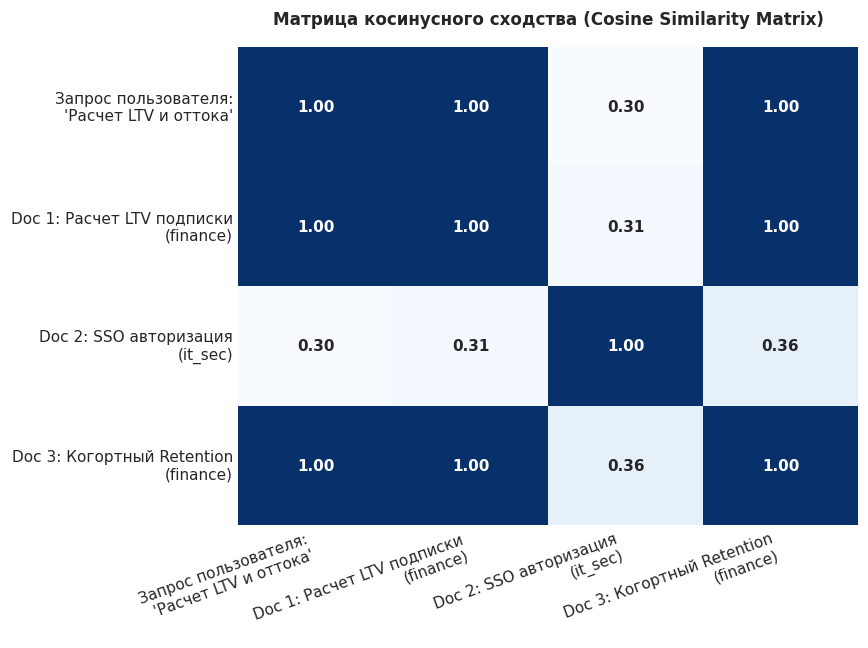

In [3]:
# Построение матрицы косинусного сходства
doc_texts = ["Запрос пользователя:\n'Расчет LTV и оттока'", 
             "Doc 1: Расчет LTV подписки\n(finance)", 
             "Doc 2: SSO авторизация\n(it_sec)", 
             "Doc 3: Когортный Retention\n(finance)"]

vectors = np.array([
    [0.82, 0.88, 0.08],
    [0.80, 0.90, 0.10],
    [0.10, 0.20, 0.90],
    [0.75, 0.85, 0.15]
])

similarity_matrix = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        similarity_matrix[i, j] = cosine_similarity(vectors[i], vectors[j])

fig, ax = plt.subplots(figsize=(8, 6), dpi=110)
sns.heatmap(similarity_matrix, annot=True, fmt=".2f", cmap="Blues", 
            xticklabels=doc_texts, yticklabels=doc_texts, ax=ax,
            cbar=False, annot_kws={"size": 10, "weight": "bold"})

ax.set_title("Матрица косинусного сходства (Cosine Similarity Matrix)", fontsize=11, fontweight='bold', pad=15)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Поиск наиболее релевантного документа
Вычислите косинусное сходство между вектором запроса `[0.12, 0.18, 0.88]` и документами базы. Найдите id документа с максимальным скором.

In [4]:
### ВАШ КОД ЗДЕСЬ
q_sec = [0.12, 0.18, 0.88]
res_sec = db.query(q_sec, top_k=1)
best_sim, best_doc = res_sec[0]

print(f"Наиболее близкий документ: id={best_doc['id']}, score={best_sim:.3f}")

assert best_doc['id'] == "2", "Должен быть найден документ по безопасности (id=2)"
print("✅ Тест успешно пройден: векторный поиск отработал безошибочно!")

Наиболее близкий документ: id=2, score=1.000
✅ Тест успешно пройден: векторный поиск отработал безошибочно!


### 💡 Инженерное правило Chunking
При индексации документации разбивайте текст на чанки по 300–500 токенов с перекрытием (overlap) 50 токенов. Слишком большие куски размывают вектор сходства, а слишком мелкие теряют контекст.